# Mean calculation verification

In this notebook, we calculate the covariance/correlation matrix of the balance indices directly by generating all trees of size n, by using the basis representations, and by using the simplified formulas (obtained in the Mathematica notebook in folder ~/mathematica). We see that the three results all agree numerically, validating the mathematical correctness of the paper and Table 2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add the parent directory to Python path so we can import from src
import sys
import os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

from src.tree_bstats.balance_index_coefficients import BalanceIndexCoefficients
from src.tree_bstats.clade_basis import clade_mean, clade_cov_matrix
from src.tree_bstats.daughter_basis import daughter_mean, daughter_cov_matrix
from src.tree_bstats.tree import Tree
from src.tree_bstats.unlabelled_tree import UnlabelledTree

# Calculate mean of balance indices for small n (up to 18)

We use three methods. The first, stored in array mean, uses the basis representations to calculate the mean. 
The second generates all trees of a given size using the UnlabelledTree class, calculates all the balance indices, and computes the weighted average (with the Yule probability weights) to find the mean of the index under the Yule model.
The last method uses the simplified equations for the mean that we found in Mathematica.  

We observe that these methods generate equivalent results, demonstrating the correctness of the formulas. 

In [2]:
mean = []
max_n = 18
labels = BalanceIndexCoefficients().get_daughter_labels()

# For all n in the range, we will compute the mean of all basis indices under daughter basis
N = range(4, max_n + 1)
for n in N:
    mu = daughter_mean(n)
    daughter_coef = BalanceIndexCoefficients(n).get_daughter_coefficients()
    matrix_of_coef= np.array(list(daughter_coef.values()))

    mean.append(np.dot(matrix_of_coef, mu))

mean = np.array(mean)

In [3]:
# Instead, we can also compute the means explicitly using all the trees of a given size
max_n = 18
all_trees = UnlabelledTree(max_n)

mean_all_trees = []

for n in np.arange(4, max_n + 1):
    _, _, balance_indices, weights = all_trees.get_data(n)
    balance_indices = np.array(balance_indices)
    unlabelledTreeLabels = all_trees.balance_index_names
    n_means = np.zeros((len(labels),))
    for i, label in enumerate(labels):
        correct_col = unlabelledTreeLabels.index(label)
        mean_stat = np.sum(balance_indices[:, correct_col] * weights) / np.sum(weights)
        n_means[i] = mean_stat
    mean_all_trees.append(n_means)
mean_all_trees = np.array(mean_all_trees)

   

Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905, 24631, 56011]


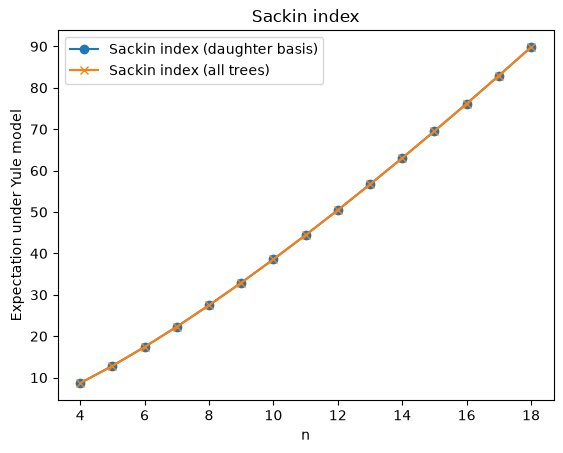

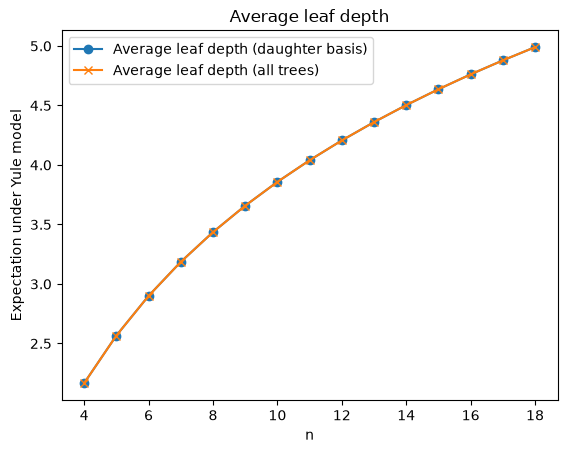

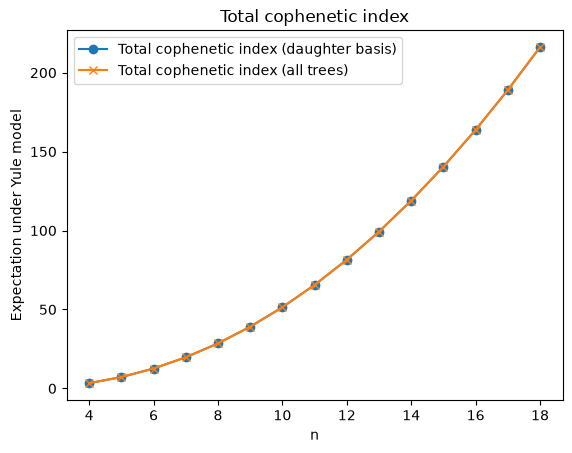

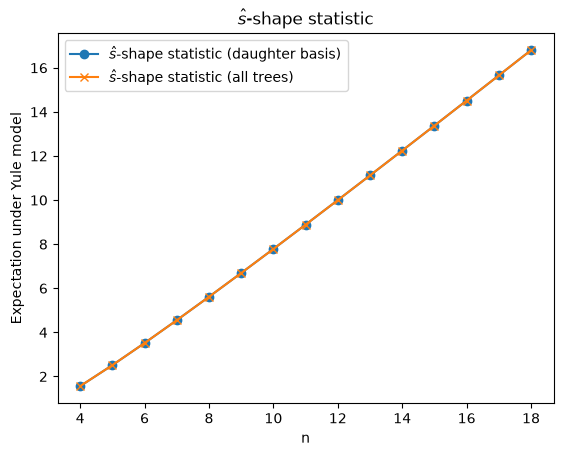

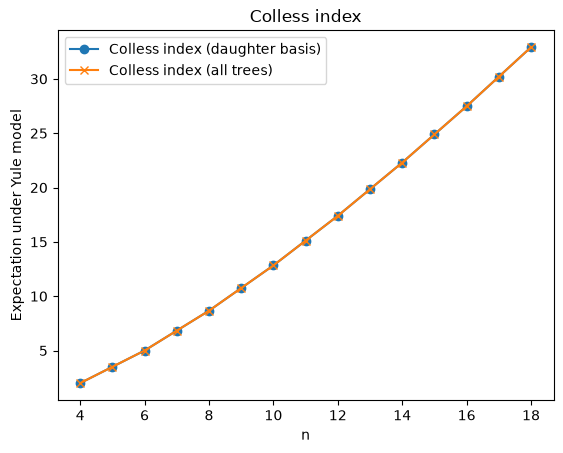

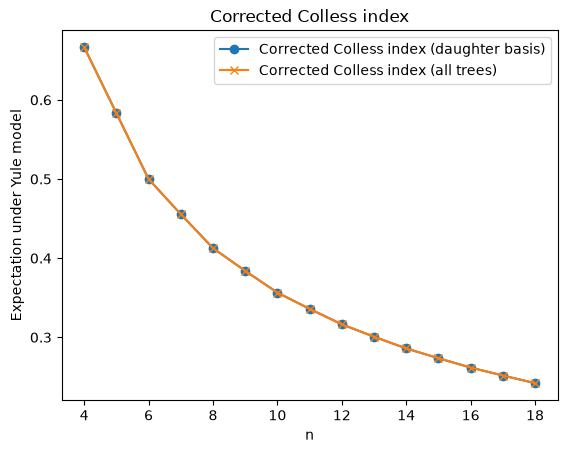

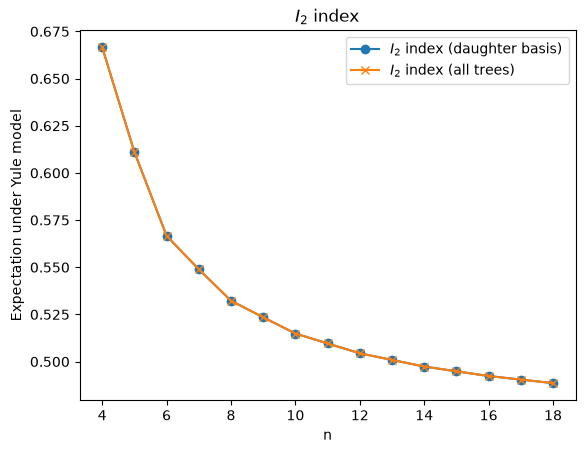

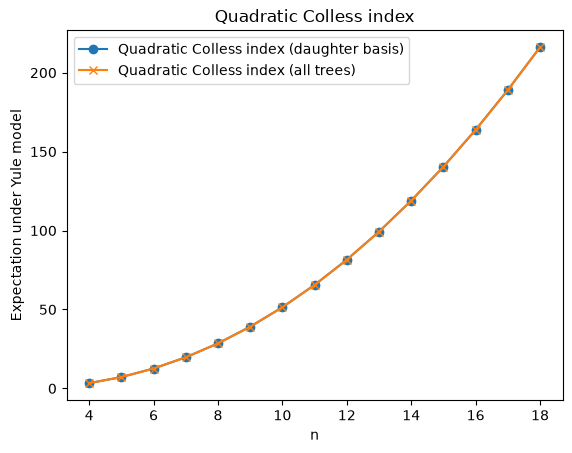

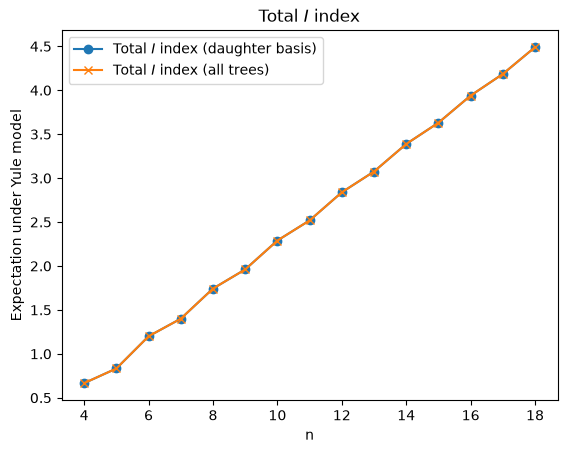

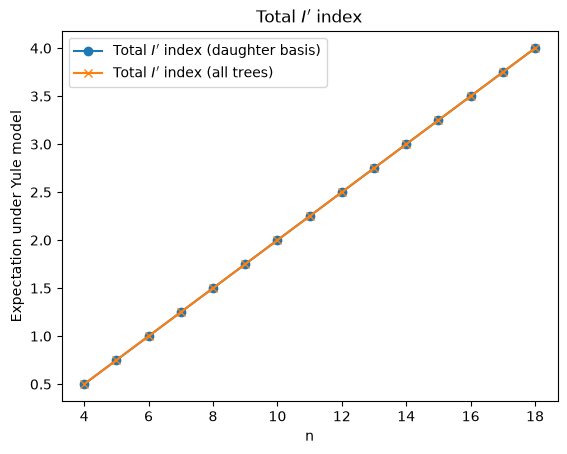

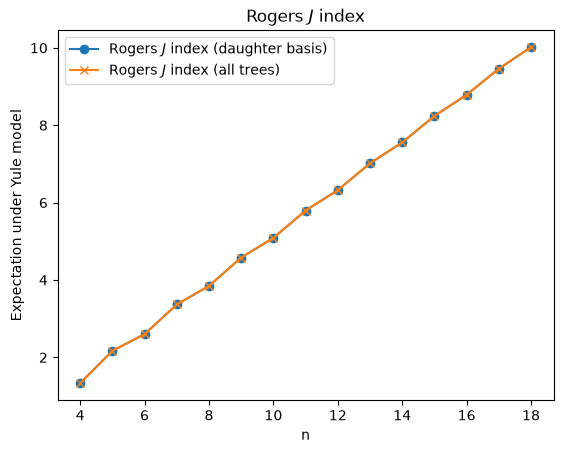

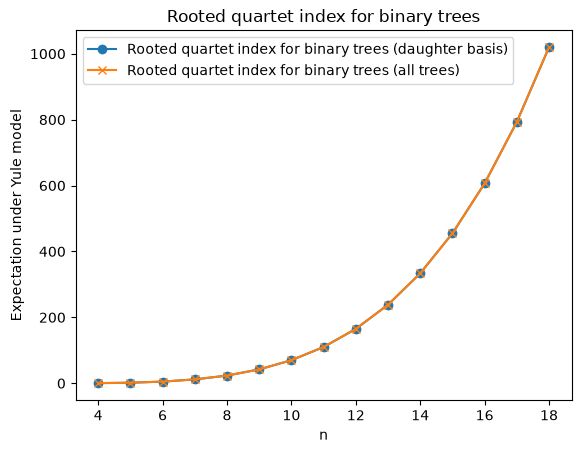

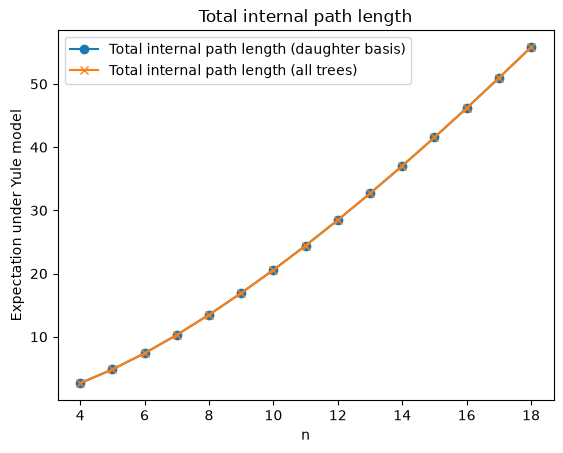

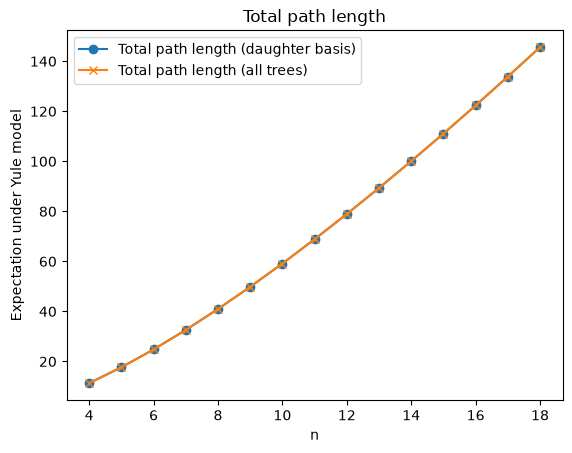

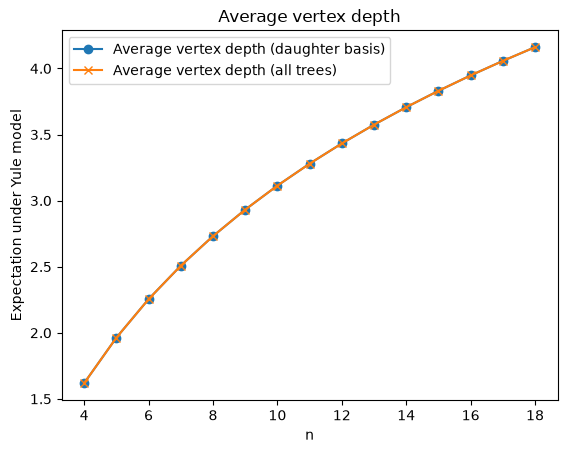

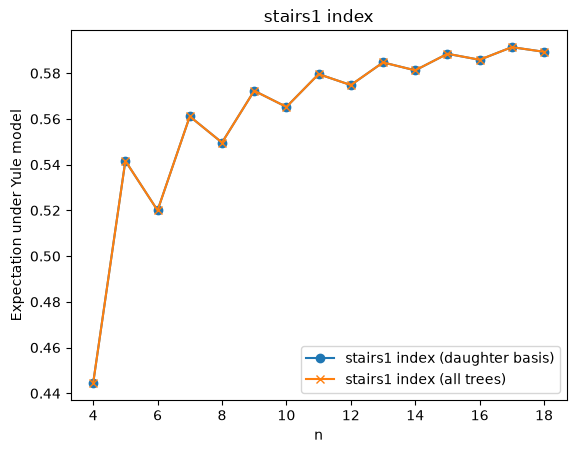

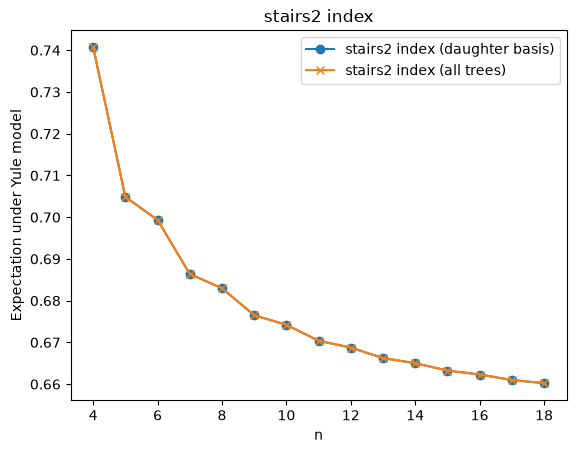

In [4]:
# Plot both methods together
for i, label in enumerate(labels):
    plt.plot(N, mean[:, i], label=label + ' (daughter basis)', marker='o')
    plt.plot(N, mean_all_trees[:, i], label=label + ' (all trees)', marker='x')
    plt.xlabel('n')
    plt.ylabel('Expectation under Yule model')
    plt.title(label)
    plt.legend()
    plt.show()

In [5]:
# Let's see what the differences are between the two methods
diff = np.max(np.abs(mean - mean_all_trees), axis=0)
max_diff_loc = np.argmax(diff)
labels[max_diff_loc], diff[max_diff_loc]

('Rooted quartet index for binary trees', np.float64(1.1368683772161603e-13))

This makes sense, because it has the largest magnitude, so the error from numerical methods will be slightly higher

In [ ]:
# As an alternative, we can compute the means using our formulas from the file mathematica/MeanCalculations.nb

# First, precompute a bunch of harmonic numbers for efficiency
maxN = 2000
harmonic_numbers = np.cumsum( 1 / np.arange(1, maxN + 1))
squared_harmonic_numbers = np.cumsum( 1 / np.arange(1, maxN + 1) ** 2)

def harmonicNumber(n, k=1):
    n = int(n)
    if k == 1 and n <= maxN:
        return harmonic_numbers[n - 1]
    elif k == 2 and n <= maxN:
        return squared_harmonic_numbers[n - 1]
    else:
        return np.sum(1 / np.arange(1, n+1) ** k)

def sackin_index(n):
    return 2 * n * (harmonicNumber(n) - 1)

def average_leaf_depth(n):
    return 2 * (harmonicNumber(n) - 1)

def total_cophenetic_index(n):
    return n * (n + 1 - 2 * harmonicNumber(n))

def s_hat_shape(n):
    return np.log(n - 1) + 2 * n * np.sum( np.log(np.arange(2, n) - 1) / np.arange(2, n) / (np.arange(2, n) + 1))

def colless_index(n):
    if n & 1 == 0:
        return n * (harmonicNumber(n / 2) - 1)
    else:
        return n * (harmonicNumber((n - 1) / 2) - 1) + 1
    
def corrected_colless_index(n):
    return colless_index(n) * 2 / (n-2) / (n-1)

def equal_weights_colless_index(n):
    if n & 1 == 0:
        return n / 6.0 / (n-2) * (4 * (harmonicNumber(n) - harmonicNumber(n / 2)) - 1 / (n - 1) )
    else:
        return (3.0 - n + 4 * n * (n - 2) * (harmonicNumber(n - 1) - harmonicNumber((n - 1) / 2))) / (6.0 * (n - 2)**2)
   
def quadratic_colless_index(n):
    return n * (n + 1 - 2 * harmonicNumber(n))

def total_I_index(n):
    m = np.floor(n / 2)
    return n * (harmonicNumber(2 * m) - harmonicNumber(m) - 5/12)

def total_I_prime_index(n):
    return n / 4 - 1 / 2
    
def rogers_J_index(n):
    if n & 1 == 0:
        return 2 * n * (harmonicNumber(n / 2 - 1) - harmonicNumber(n - 1) + 1)
    else:
        return 2 * n * (harmonicNumber((n-1) / 2) - harmonicNumber(n - 1) + 1) - 2

def rooted_quartet_binary_index(n):
    return 1 / 72 * n * (n - 1) * (n - 2) * (n - 3)

def total_internal_path_length(n):
    return 2 - 4 * n + 2 * n * harmonicNumber(n)

def total_path_length(n):
    return 2 - 6 * n + 4 * n * harmonicNumber(n)

def average_vertex_depth(n):
    return total_path_length(n) / (2 * n - 1)

def stairs1(n):
    return rogers_J_index(n) / (n - 1)

def g(k):
    if k & 1 == 0:
        return (1 - k - 2 * k * harmonicNumber(k / 2) + 2 * k * harmonicNumber(k)) / ((k - 1))
    else:
        return (1 - k - 2 * k * harmonicNumber((k - 1) / 2) + 2 * k * harmonicNumber(k - 1)) / ((k - 1))
    
def stairs2(n):
    return (1 / (n- 1)) * ((g(n) + 2 * n * sum( g(k) / k / (k + 1) for k in range(2, n))))


In [11]:
# Now we can compute the means using the formulas
mean_functions = [
    sackin_index,
    average_leaf_depth,
    total_cophenetic_index,
    s_hat_shape,
    colless_index,
    corrected_colless_index,
    equal_weights_colless_index,
    quadratic_colless_index,
    total_I_index,
    total_I_prime_index,
    rogers_J_index,
    rooted_quartet_binary_index,
    total_internal_path_length,
    total_path_length,
    average_vertex_depth,
    stairs1,
    stairs2
]


max_n = 18
N = range(4, max_n + 1)
mean_formula = np.zeros((len(N), len(mean_functions)))
for i, n in enumerate(N):
    for j, func in enumerate(mean_functions):
        mean_formula[i, j] = func(n)


In [12]:
# Compare the arrays

np.abs(mean_formula - mean_all_trees).max(axis=0)

array([2.84217094e-14, 1.33226763e-15, 2.84217094e-14, 5.32907052e-15,
       1.42108547e-14, 1.11022302e-16, 7.77156117e-16, 8.52651283e-14,
       1.33226763e-14, 8.88178420e-16, 2.66453526e-14, 1.13686838e-13,
       2.13162821e-14, 5.68434189e-14, 1.77635684e-15, 1.66533454e-15,
       6.66133815e-16])

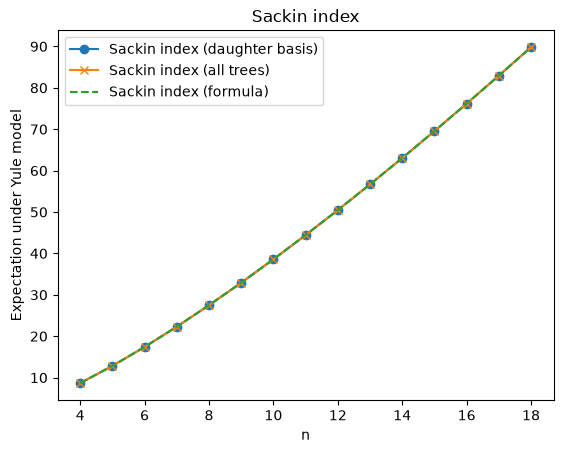

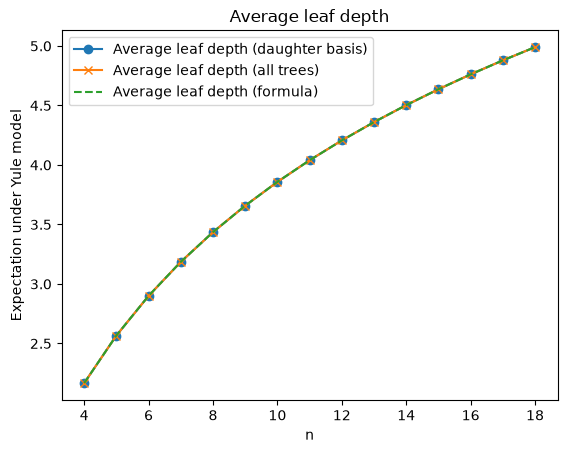

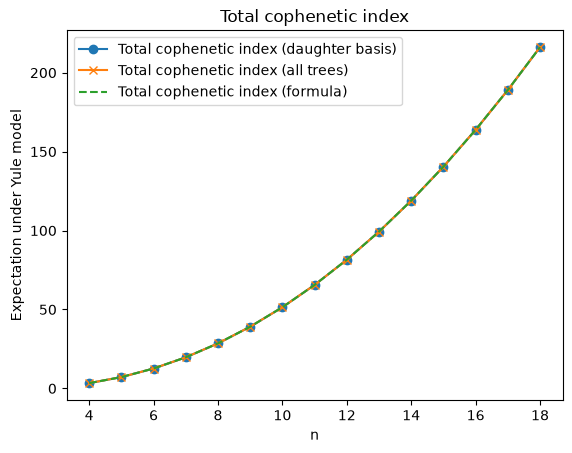

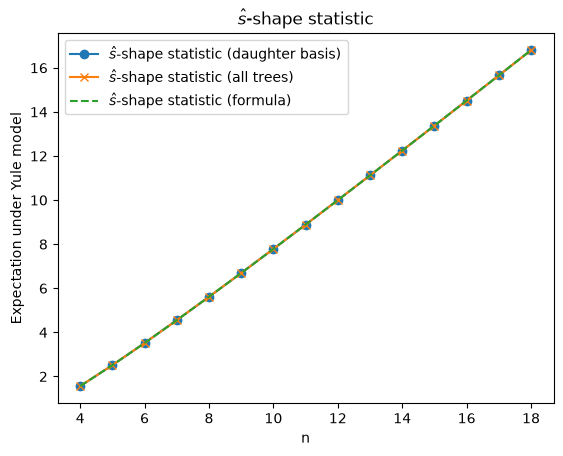

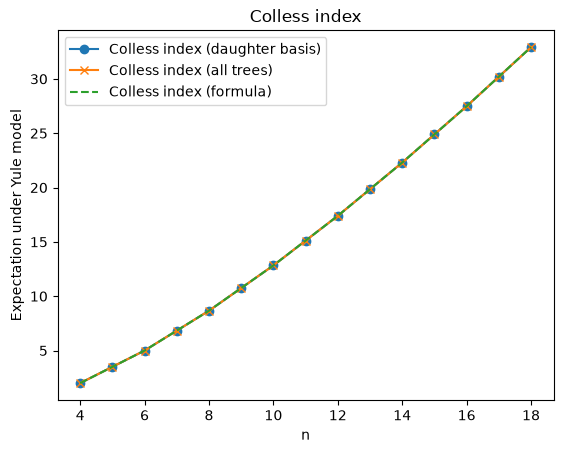

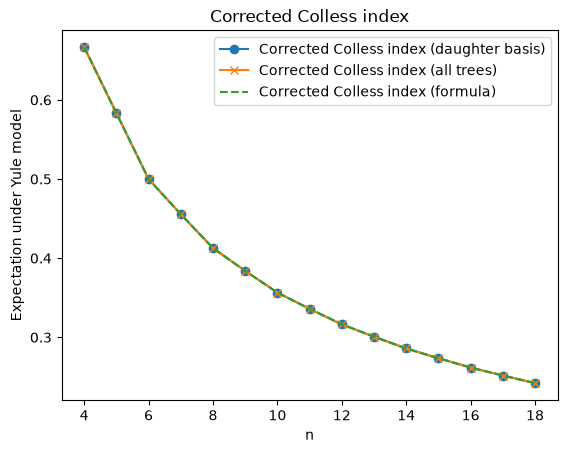

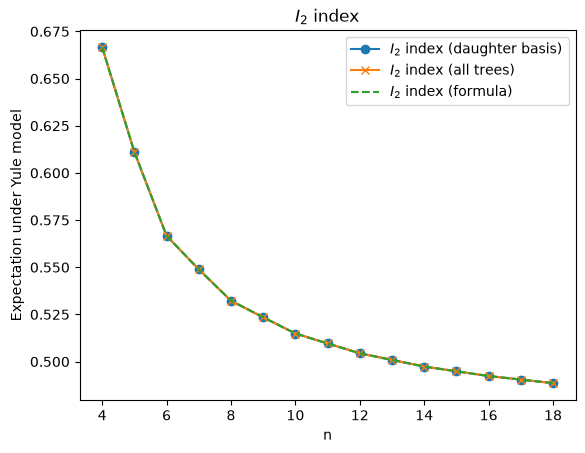

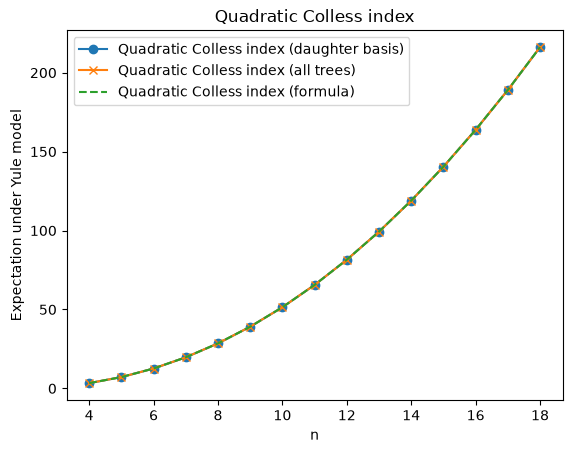

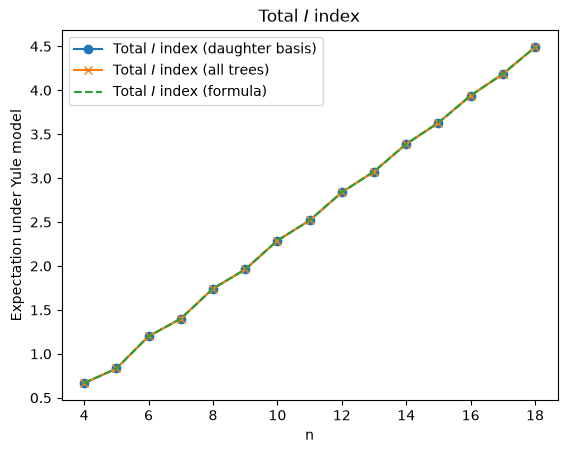

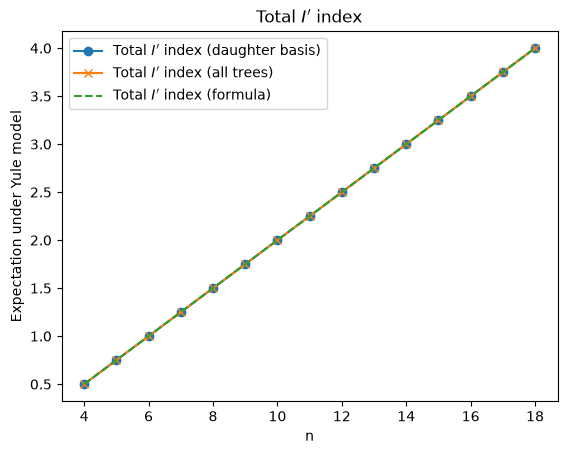

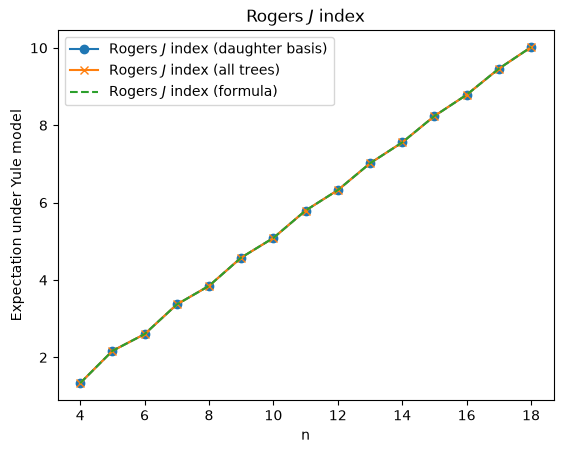

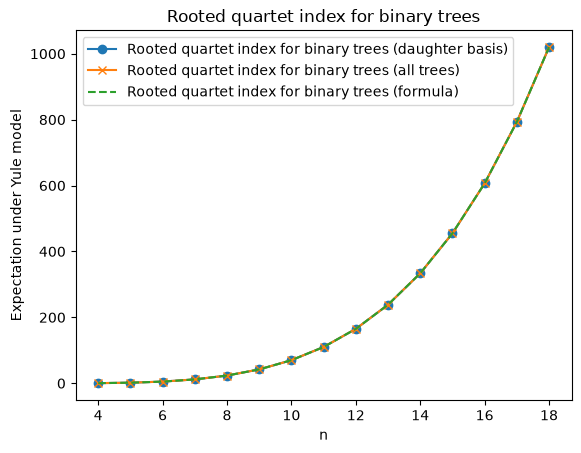

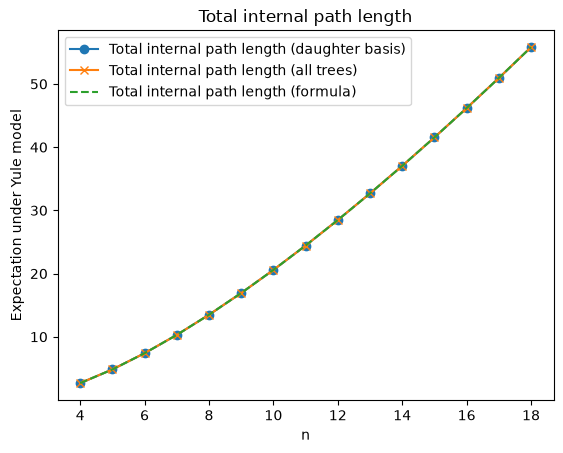

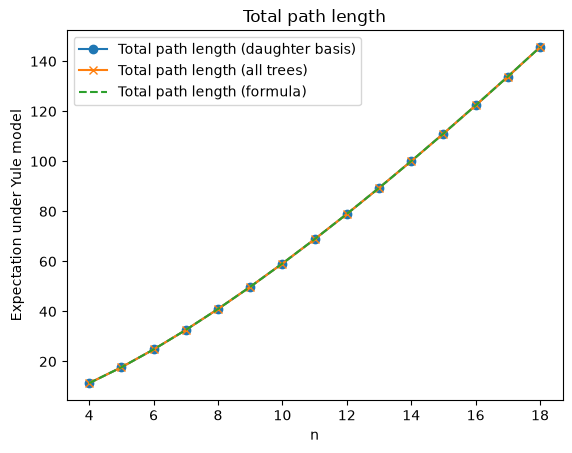

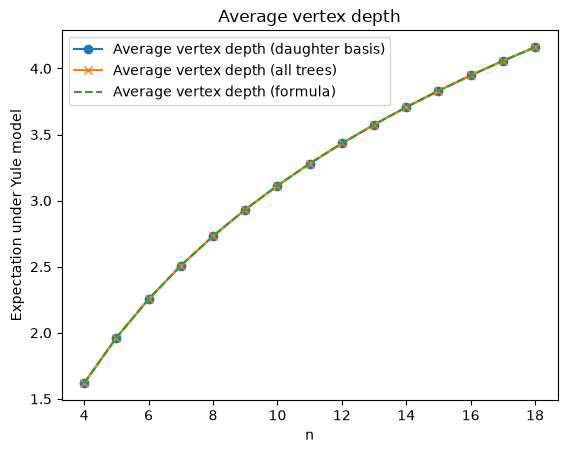

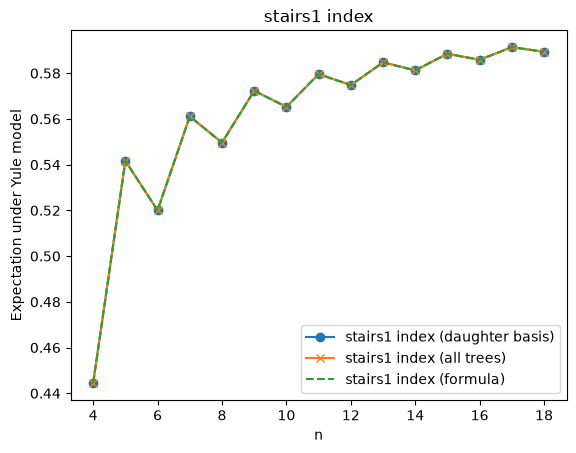

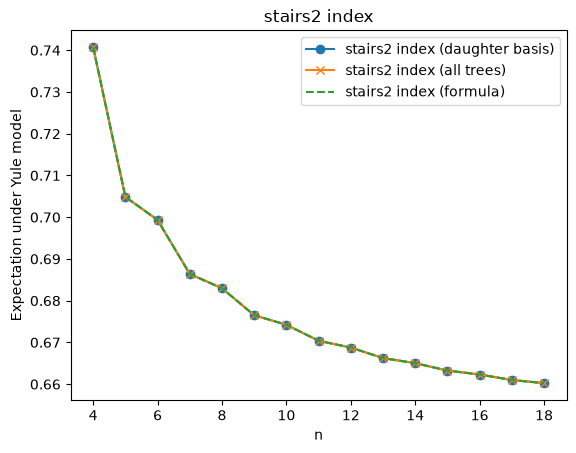

In [13]:
# Plot all methods together
for i, label in enumerate(labels):
    plt.plot(N, mean[:, i], label=label + ' (daughter basis)', marker='o')
    plt.plot(N, mean_all_trees[:, i], label=label + ' (all trees)', marker='x')
    plt.plot(N, mean_formula[:, i], label=label + ' (formula)', linestyle='--')
    plt.xlabel('n')
    plt.ylabel('Expectation under Yule model')
    plt.title(label)
    plt.legend()
    plt.show()